In [1]:
from pathlib import Path
import numpy as np
from scipy.signal import find_peaks, savgol_filter
from session_data import SessionData
from mikrotik_metadata import *
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

In [20]:
def process_csi_data(H: np.ndarray, sample_rate: float = 0.4, plot: bool = False) -> np.ndarray:
    """Process CSI data by removing outliers and smoothing.

    This method:
    1. Unwraps phase and calculates phase velocity
    2. Detects and removes measurements with anomalous phase jumps (first pass)
    3. Detects and removes magnitude change outliers (second pass)
    4. Detects and removes remaining magnitude change outliers (third pass)
    5. Applies Savitzky-Golay filtering for smoothing

    Args:
        H: Complex CSI data of shape (num_measurements, num_subcarriers)
        sample_rate: Sampling rate in Hz (default: 0.4 Hz)
        plot: If True, visualizes the peak detection process

    Returns:
        Processed CSI data (may have fewer measurements due to outlier removal)
    """
    if H.size == 0 or len(H.shape) != 2:
        return H

    # Antennas to check for outliers 
    remove_peaks_ant_p1 = [2, 3, 4, 6, 7, 8, 11, 13, 21, 23, 25, 27]
    remove_peaks_ant_p2 = valid_antennas

    # First pass: Remove major outliers
    unwrapped_phase = np.unwrap(np.angle(H), axis=0)
    phase_velocity = np.diff(unwrapped_phase, axis=0)

    indexes_to_remove = []
    for i in remove_peaks_ant_p1:
        if i >= phase_velocity.shape[1]:
            continue
            
        pv = phase_velocity[:, i]
        
        # Adaptive threshold based on standard deviation
        min_peak_prominence = np.std(np.abs(pv)) * 4
        min_peak_distance = int(max(1, round(0.005 / sample_rate)))  # Minimum 5ms between peaks
        
        # Find peaks in absolute phase velocity
        peaks, _ = find_peaks(np.abs(pv), 
                                prominence=min_peak_prominence,
                                distance=min_peak_distance)
        
        # Remove peak and neighboring measurements
        for peak in peaks:
            indexes_to_remove.extend([peak-1, peak, peak+1, peak+2])  # +2 because diff reduces size by 1

    # Remove duplicates and invalid indexes
    indexes_to_remove = np.unique(indexes_to_remove)
    indexes_to_remove = indexes_to_remove[(indexes_to_remove >= 0) & (indexes_to_remove < len(H))]

    # Plot first pass: Phase velocity peaks
    if plot and len(remove_peaks_ant_p1) > 0:
        num_plots = min(6, len(remove_peaks_ant_p1))  # Plot up to 6 antennas
        fig, axes = plt.subplots(num_plots, 1, figsize=(15, 3*num_plots))
        if num_plots == 1:
            axes = [axes]
        fig.suptitle('First Pass: Phase Velocity Peak Detection', fontsize=14, fontweight='bold')
        
        for idx, ant_idx in enumerate(remove_peaks_ant_p1[:num_plots]):
            if ant_idx >= phase_velocity.shape[1]:
                continue
                
            pv = phase_velocity[:, ant_idx]
            min_peak_prominence = np.std(np.abs(pv)) * 4
            min_peak_distance = int(max(1, round(0.005 / sample_rate)))
            peaks, properties = find_peaks(np.abs(pv), 
                                          prominence=min_peak_prominence,
                                          distance=min_peak_distance)
            
            axes[idx].plot(np.abs(pv), label='|Phase Velocity|', alpha=0.7)
            axes[idx].plot(peaks, np.abs(pv[peaks]), 'rx', markersize=10, label=f'Peaks ({len(peaks)} found)')
            axes[idx].axhline(y=min_peak_prominence, color='g', linestyle='--', 
                            label=f'Threshold={min_peak_prominence:.2f}')
            axes[idx].set_ylabel(f'Ant {ant_idx}')
            axes[idx].legend(loc='upper right')
            axes[idx].grid(True, alpha=0.3)
            
        axes[-1].set_xlabel('Measurement Index')
        plt.tight_layout()
        plt.show()
        
        print(f"First pass: Removing {len(indexes_to_remove)} measurements")

    if len(indexes_to_remove) > 0:
        H = np.delete(H, indexes_to_remove, axis=0)

    # Second pass: Remove remaining outliers based on magnitude changes
    if H.shape[0] > 2:
        magnitude = np.abs(H)
        magnitude_change = np.diff(magnitude, axis=0)
        indexes_to_remove = []
        for i in remove_peaks_ant_p2:
            if i >= magnitude_change.shape[1]:
                continue
                
            mag_change = magnitude_change[:, i]
            
            # Threshold for magnitude changes (matching plot visualization)
            min_peak_prominence = np.std(np.abs(mag_change)) * 5.0
            min_peak_distance = int(max(1, round(0.005 / sample_rate)))
            
            peaks, _ = find_peaks(np.abs(mag_change), 
                                    prominence=min_peak_prominence,
                                    distance=min_peak_distance)
            
            for peak in peaks:
                indexes_to_remove.extend([peak-1, peak, peak+1, peak+2])
        
        indexes_to_remove = np.unique(indexes_to_remove)
        indexes_to_remove = indexes_to_remove[(indexes_to_remove >= 0) & (indexes_to_remove < len(H))]
        
        # Plot second pass: Magnitude change peaks
        if plot and len(remove_peaks_ant_p1) > 0:
            num_plots = min(6, len(remove_peaks_ant_p1))
            fig, axes = plt.subplots(num_plots, 1, figsize=(15, 3*num_plots))
            if num_plots == 1:
                axes = [axes]
            fig.suptitle('Second Pass: Magnitude Change Peak Detection', fontsize=14, fontweight='bold')
            
            for idx, ant_idx in enumerate(remove_peaks_ant_p1[:num_plots]):
                if ant_idx >= magnitude_change.shape[1]:
                    continue
                    
                mag_change = magnitude_change[:, ant_idx]
                min_peak_prominence = np.std(np.abs(mag_change)) * 5.0
                min_peak_distance = 1
                peaks, properties = find_peaks(np.abs(mag_change), 
                                              prominence=min_peak_prominence,
                                              distance=min_peak_distance)
                
                axes[idx].plot(np.abs(mag_change), label='|Magnitude Change|', alpha=0.7)
                axes[idx].plot(peaks, np.abs(mag_change[peaks]), 'rx', markersize=10, 
                             label=f'Peaks ({len(peaks)} found)')
                axes[idx].axhline(y=min_peak_prominence, color='g', linestyle='--', 
                                label=f'Threshold={min_peak_prominence:.2f}')
                axes[idx].set_ylabel(f'Ant {ant_idx}')
                axes[idx].legend(loc='upper right')
                axes[idx].grid(True, alpha=0.3)
                
            axes[-1].set_xlabel('Measurement Index')
            plt.tight_layout()
            plt.show()
            
            print(f"Second pass: Removing {len(indexes_to_remove)} measurements")
        
        if len(indexes_to_remove) > 0:
            H = np.delete(H, indexes_to_remove, axis=0)

    # Third pass: Another magnitude change pass to catch remaining outliers
    if H.shape[0] > 2:
        magnitude = np.abs(H)
        magnitude_change = np.diff(magnitude, axis=0)
        indexes_to_remove = []
        for i in remove_peaks_ant_p2:
            if i >= magnitude_change.shape[1]:
                continue
                
            mag_change = magnitude_change[:, i]
            
            # Same threshold for remaining outliers (matching plot visualization)
            min_peak_prominence = np.std(np.abs(mag_change)) * 5.0
            min_peak_distance = int(max(1, round(0.005 / sample_rate)))
            
            peaks, _ = find_peaks(np.abs(mag_change), 
                                    prominence=min_peak_prominence,
                                    distance=min_peak_distance)
            
            for peak in peaks:
                indexes_to_remove.extend([peak-1, peak, peak+1, peak+2])
        
        indexes_to_remove = np.unique(indexes_to_remove)
        indexes_to_remove = indexes_to_remove[(indexes_to_remove >= 0) & (indexes_to_remove < len(H))]
        
        # Plot third pass: Magnitude change peaks (second round)
        if plot and len(remove_peaks_ant_p1) > 0:
            num_plots = min(6, len(remove_peaks_ant_p1))
            fig, axes = plt.subplots(num_plots, 1, figsize=(15, 3*num_plots))
            if num_plots == 1:
                axes = [axes]
            fig.suptitle('Third Pass: Magnitude Change Peak Detection (Round 2)', fontsize=14, fontweight='bold')
            
            for idx, ant_idx in enumerate(remove_peaks_ant_p1[:num_plots]):
                if ant_idx >= magnitude_change.shape[1]:
                    continue
                    
                mag_change = magnitude_change[:, ant_idx]
                min_peak_prominence = np.std(np.abs(mag_change)) * 5.0
                min_peak_distance = 1
                peaks, properties = find_peaks(np.abs(mag_change), 
                                              prominence=min_peak_prominence,
                                              distance=min_peak_distance)
                
                axes[idx].plot(np.abs(mag_change), label='|Magnitude Change|', alpha=0.7)
                axes[idx].plot(peaks, np.abs(mag_change[peaks]), 'rx', markersize=10, 
                             label=f'Peaks ({len(peaks)} found)')
                axes[idx].axhline(y=min_peak_prominence, color='g', linestyle='--', 
                                label=f'Threshold={min_peak_prominence:.2f}')
                axes[idx].set_ylabel(f'Ant {ant_idx}')
                axes[idx].legend(loc='upper right')
                axes[idx].grid(True, alpha=0.3)
                
            axes[-1].set_xlabel('Measurement Index')
            plt.tight_layout()
            plt.show()
            
            print(f"Third pass: Removing {len(indexes_to_remove)} measurements")
        
        if len(indexes_to_remove) > 0:
            H = np.delete(H, indexes_to_remove, axis=0)

    # Apply Savitzky-Golay filter for smoothing
    if H.shape[0] >= 9:  # Need at least window_length points
        window_length = 9  # Must be odd
        poly_order = 1
        
        smoothed_channel = np.zeros_like(H, dtype=complex)
        for i in range(H.shape[1]):
            # Filter real and imaginary parts separately
            smoothed_channel[:, i] = savgol_filter(H[:, i].real, window_length, poly_order) + \
                                    1j * savgol_filter(H[:, i].imag, window_length, poly_order)
        
        H = smoothed_channel

    return H

In [3]:
session_dir = Path("../data/2025-11-20/session_135938")

session = SessionData.from_directory(session_dir, channel=2)
session.load_all_router_batches()

channel_data = session.get_csi_data(averaged=False)
channel_data_avg = session.get_csi_data(averaged=True)

print(f"Original data shape: {channel_data.shape}")

Original data shape: (21581, 16)


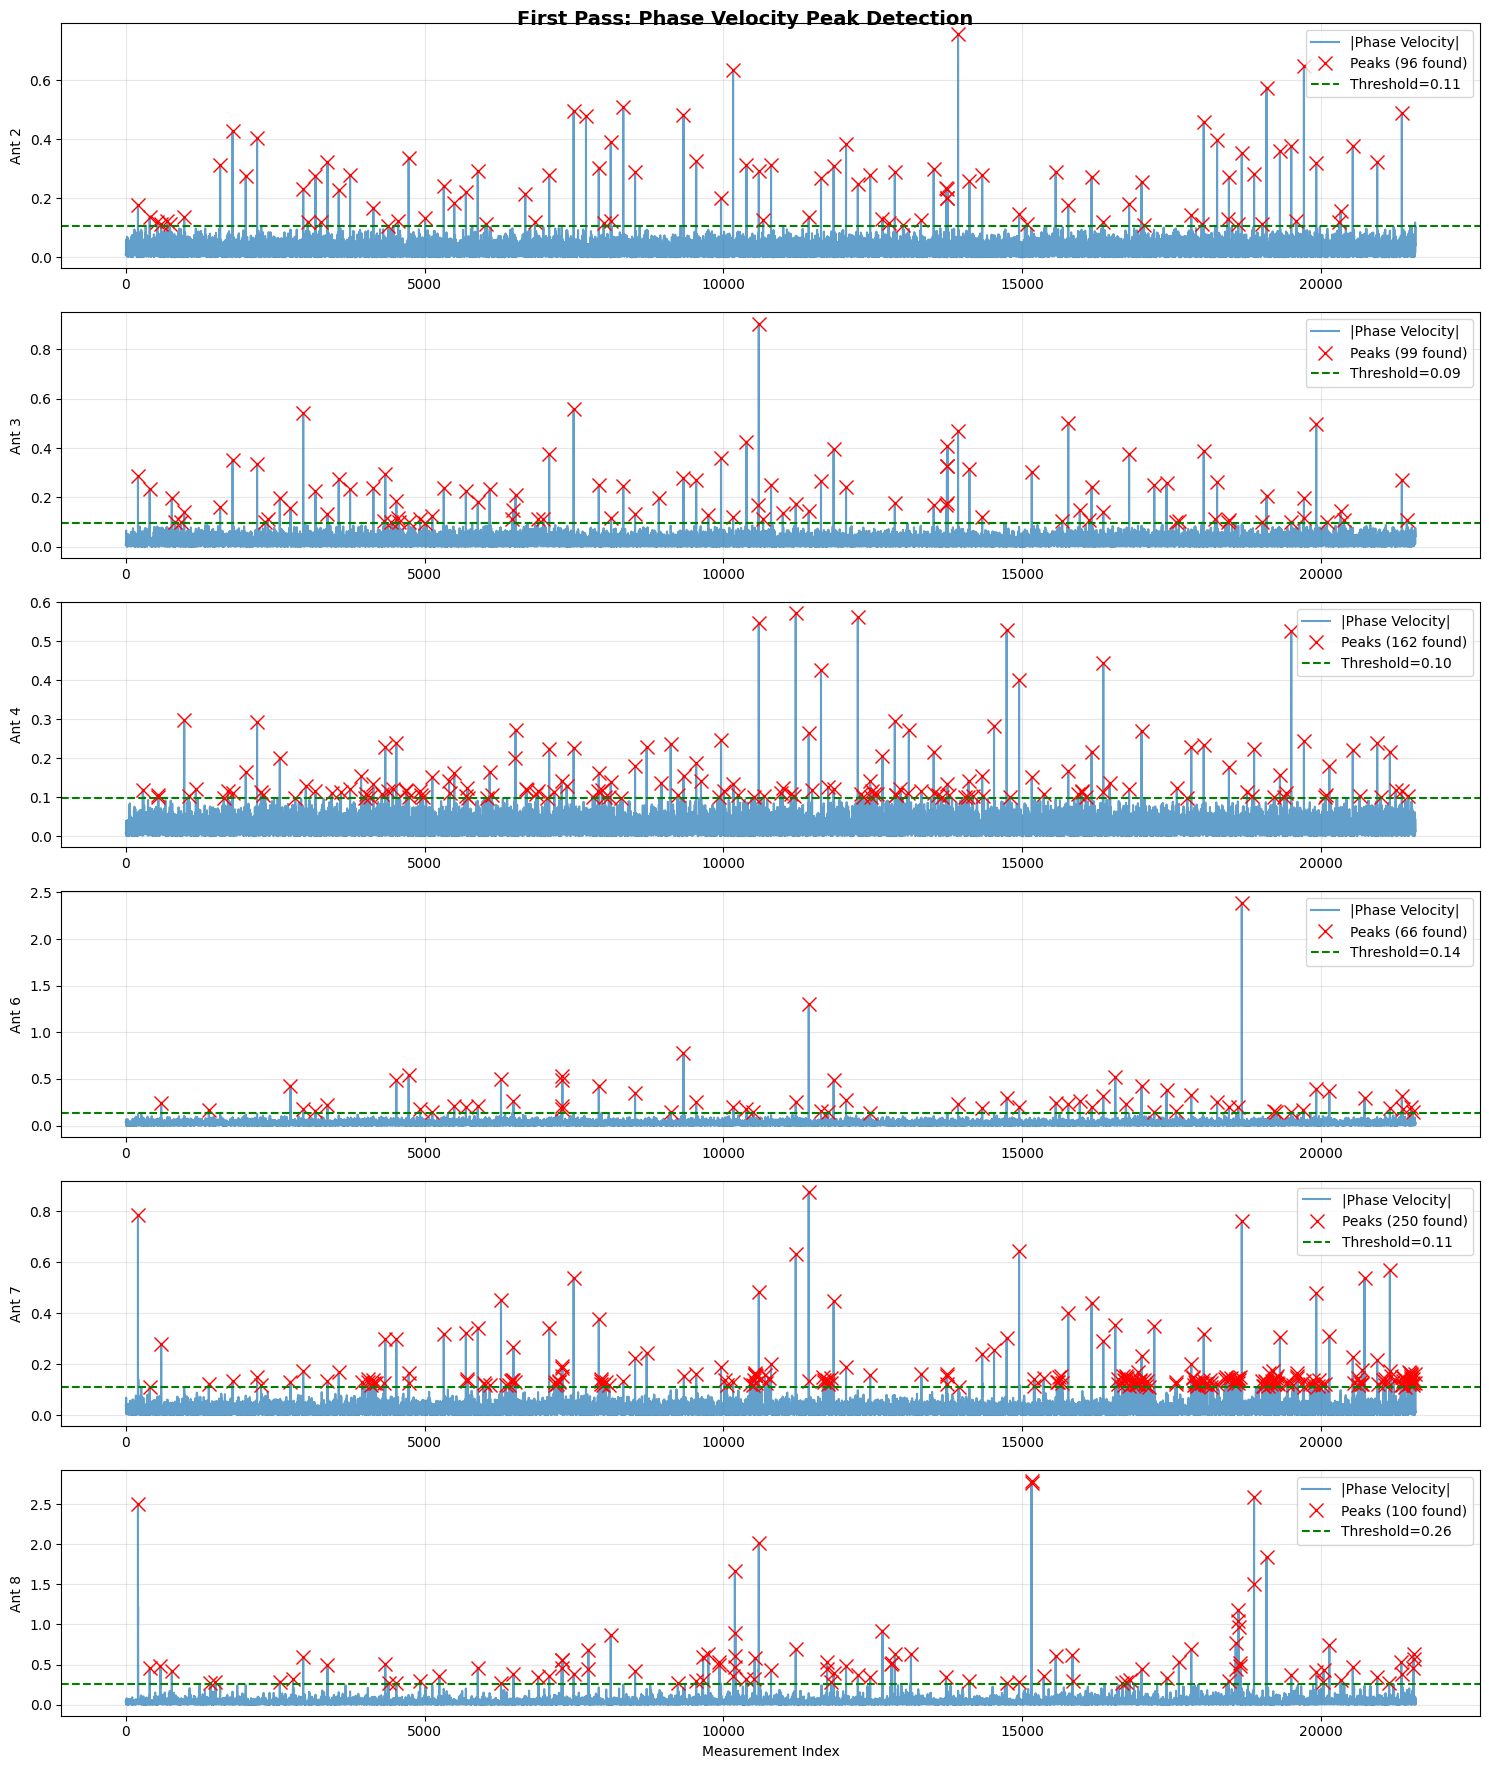

First pass: Removing 1924 measurements


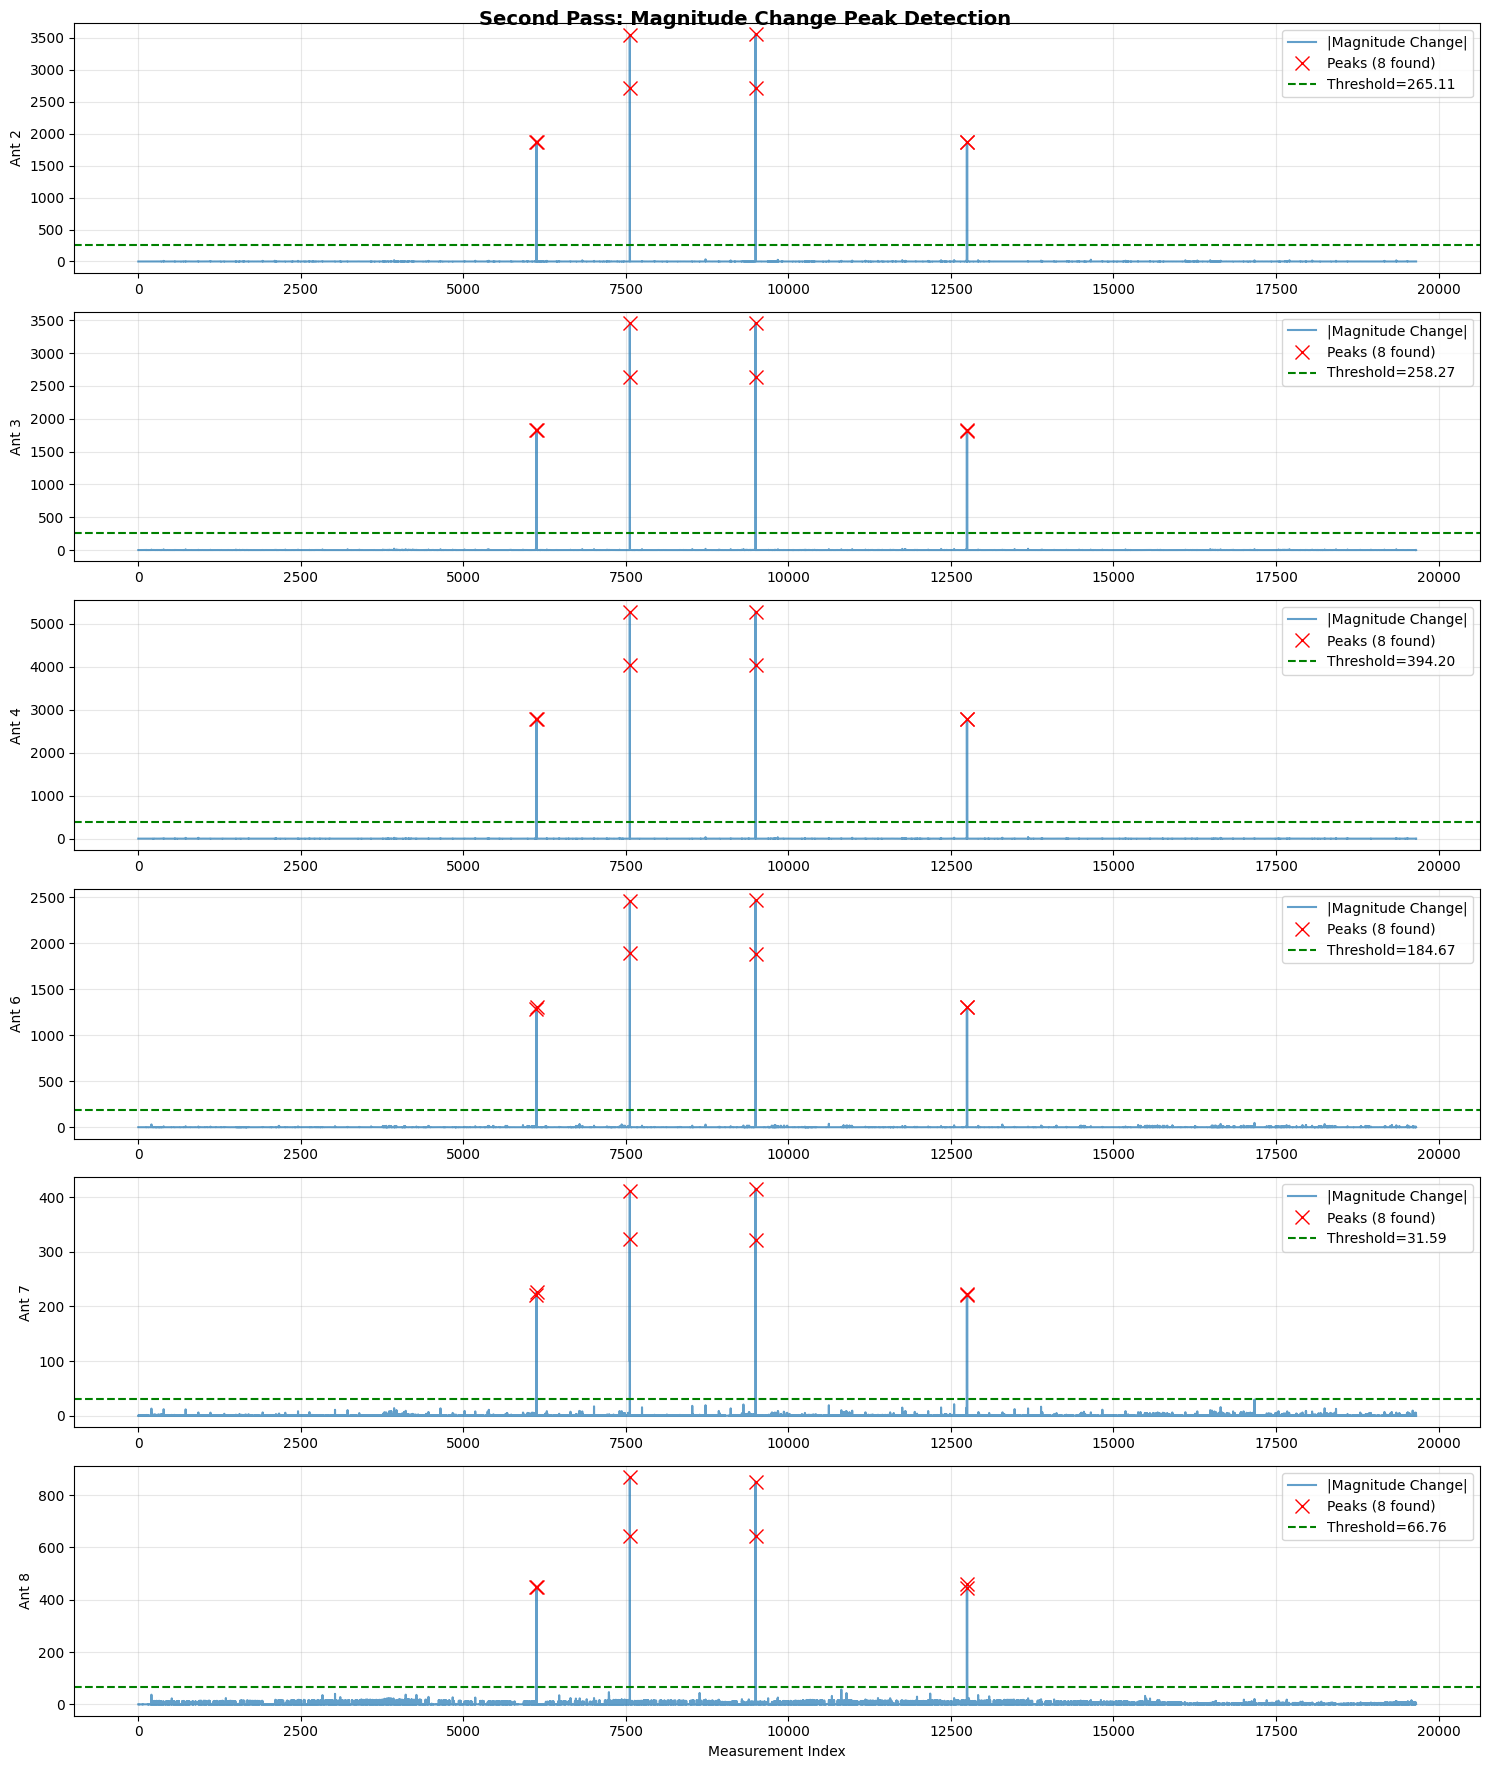

Second pass: Removing 985 measurements


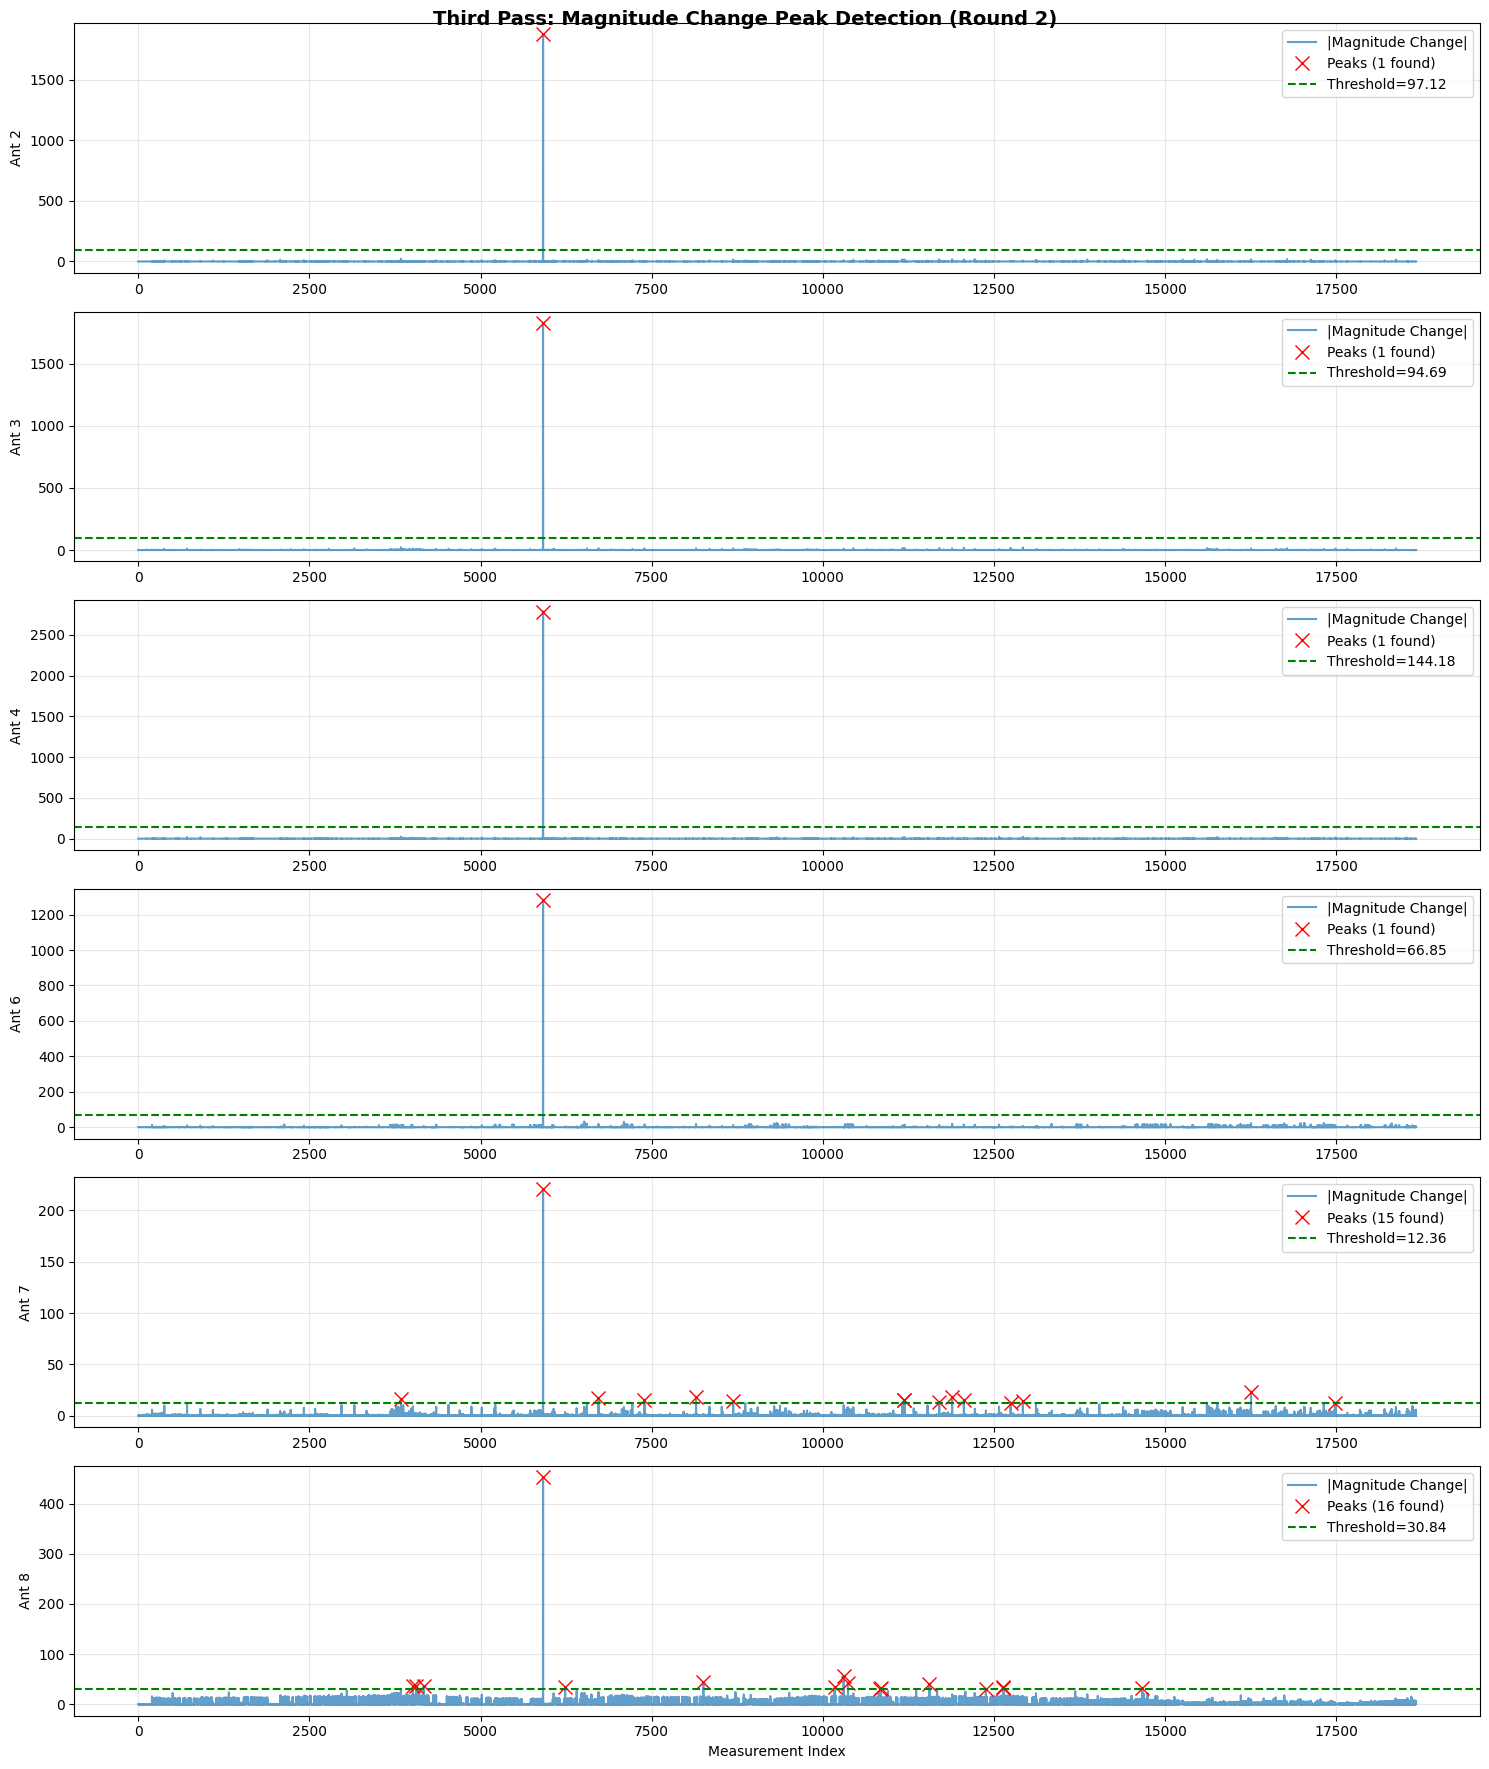

Third pass: Removing 812 measurements

Processed data shape: (17860, 16)
Measurements removed: 3721


In [21]:
# Process CSI data with peak detection visualization
processed_data = process_csi_data(channel_data, sample_rate=0.4, plot=True)

print(f"\nProcessed data shape: {processed_data.shape}")
print(f"Measurements removed: {channel_data.shape[0] - processed_data.shape[0]}")


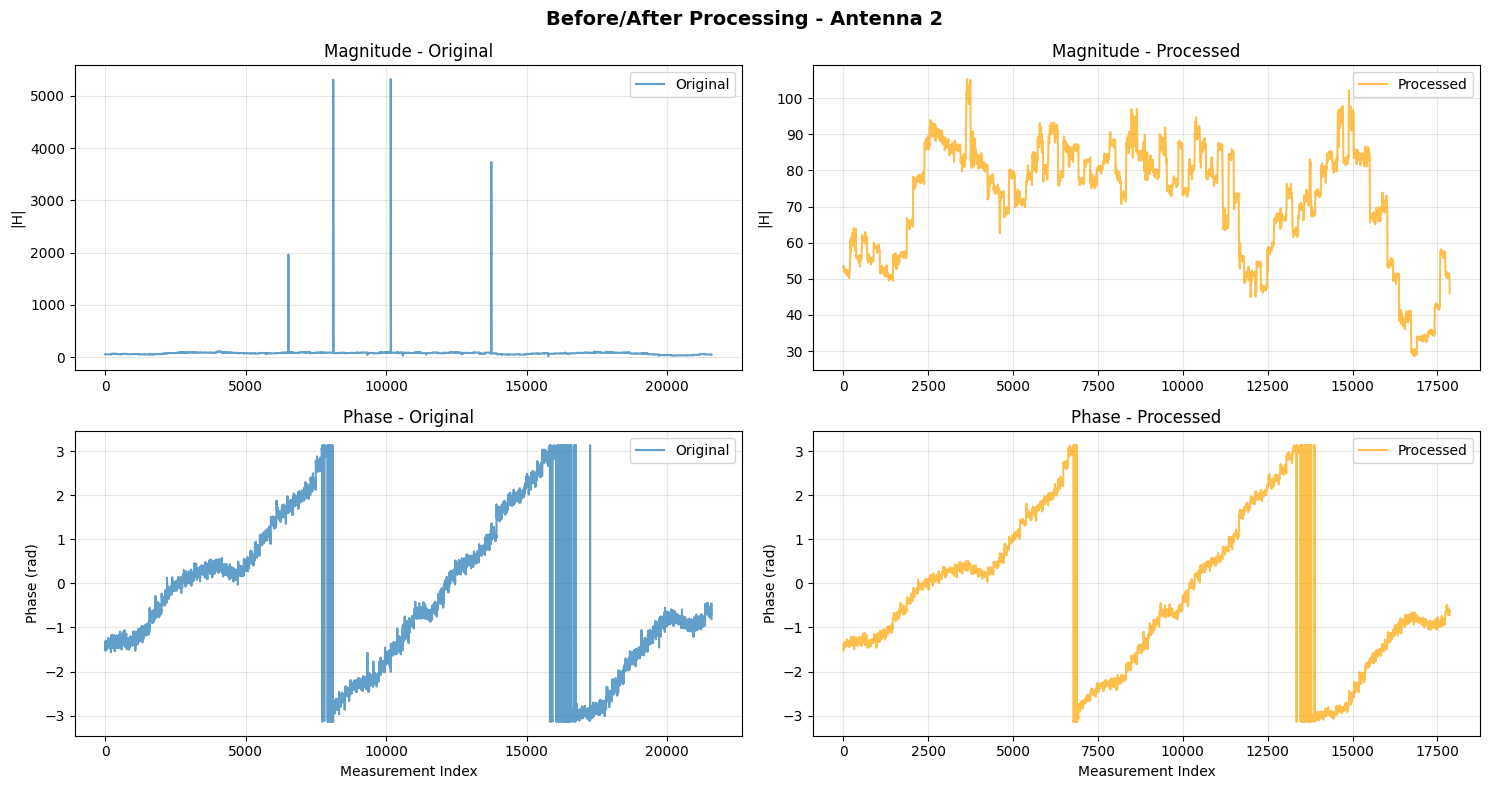

In [22]:
# Compare original vs processed data for a specific antenna
ant_idx = 2  # Change this to view different antennas

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
fig.suptitle(f'Before/After Processing - Antenna {ant_idx}', fontsize=14, fontweight='bold')

# Original data
axes[0, 0].plot(np.abs(channel_data[:, ant_idx]), label='Original', alpha=0.7)
axes[0, 0].set_title('Magnitude - Original')
axes[0, 0].set_ylabel('|H|')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

axes[1, 0].plot(np.angle(channel_data[:, ant_idx]), label='Original', alpha=0.7)
axes[1, 0].set_title('Phase - Original')
axes[1, 0].set_ylabel('Phase (rad)')
axes[1, 0].set_xlabel('Measurement Index')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

# Processed data
axes[0, 1].plot(np.abs(processed_data[:, ant_idx]), label='Processed', alpha=0.7, color='orange')
axes[0, 1].set_title('Magnitude - Processed')
axes[0, 1].set_ylabel('|H|')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

axes[1, 1].plot(np.angle(processed_data[:, ant_idx]), label='Processed', alpha=0.7, color='orange')
axes[1, 1].set_title('Phase - Processed')
axes[1, 1].set_ylabel('Phase (rad)')
axes[1, 1].set_xlabel('Measurement Index')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].legend()

plt.tight_layout()
plt.show()
